In [ ]:
from Code.network_expansion import *
from Code.externalize_results import *
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import bipartite

# Expansions from primordial seed sets
write_outputs = True
max_generation = 1000
name = 'primordial'

# define chemical scope
reaction_scope = get_sides(import_reaction_file())
compound_scope = set.union(*reaction_scope.stack())
seed_scope = seed_candidates.loc[seed_candidates.index.isin(compound_scope)]
seeds = list(seed_scope.index)

# run network expansion
result = expand_from_seed_set(seeds=seeds, reactions=reaction_scope, max_gen=max_generation)
write_expansion_csv(result, filename=name, destination_dir='Output/'+name+'/')
result = generate_annotated_bipartite_edge_list(result)
# summary = result
transition_gen = result['chiral_fraction'].where(lambda x: x>0.5).idxmin()
print(f"Transition Step: {transition_gen}")
#transition_gen = 10
transition_edge_df = result['bipartite_edgelist'].query('step <= @transition_gen').copy(deep=True)
print(transition_edge_df)
networks = {i: nx.from_pandas_edgelist(transition_edge_df[transition_edge_df[i]], 
        source='source', target='target', edge_attr=True, create_using=nx.DiGraph())
        for i in ['impactful_precursor','immediate_precursor','directed']}
compound_nodes = {i: set(j.nodes()).difference(reaction_scope.index) for i,j in networks.items()}
networks_uni = {i: bipartite.projected_graph(networks[i], nodes=compound_nodes[i]) for i in networks.keys()}


In [105]:
#print(result)
print(type(result["participants"]["new compounds"]))

print(result["participants"]["new compounds"])


<class 'pandas.core.series.Series'>
0     {C00305, C00205, C01330, C17023, C00488, C0654...
1     {C00603, C06393, C03401, C03600, C19697, C0055...
2     {C03082, C04399, C00099, C03939, C03409, C0060...
3     {C20258, C10899, C22383, C03044, C21643, C0572...
4     {C06326, C16653, C21389, C00114, C02656, C2031...
5     {C12293, C00645, C03367, C04114, C17694, C0263...
6     {C04187, C00182, C10483, C00705, C16649, C1283...
7     {C04353, C20995, C20353, C03617, C21717, C0560...
8     {C00261, C16776, C22513, C16352, C01414, C2290...
9     {C03461, C21728, C04500, C06670, C21711, C1189...
10    {C19795, C22529, C04232, C20936, C21254, C2068...
11    {C03058, C05620, C11038, C01942, C00888, C1967...
12    {C09818, C22245, C05657, C20470, C10469, C1802...
13    {C04265, C01917, C10936, C20628, C06179, C1640...
14    {C17675, C16190, C04088, C03840, C20340, C1657...
15    {C21734, C10513, C12376, C11876, C04900, C1385...
16    {C06972, C00757, C21393, C01943, C02793, C2046...
17    {C0838

In [171]:
from matplotlib.colors import Normalize, to_hex, BoundaryNorm
import matplotlib

def gna(G, attr): return nx.get_node_attributes(G, attr)

def colorize_Series(S, cmap='cet_CET_C6s'):
    # S should be list-like, or a dict, or a series.... of numbers.
    color_map = matplotlib.colormaps[cmap]
    def float_norm(x): return(Normalize(vmin=x.min(), vmax=x.max()))
    def boundary_norm(x): return(BoundaryNorm(boundaries=list(range(x.min(), x.max()+1, 1)), ncolors=color_map.N))
    if type(S)!=pd.Series:
        S = pd.Series(S)
    if S.dtype==pd.Float64Dtype():
        c_ser = pd.Series(map(tuple, color_map(float_norm(S)(list(S.values)))), index=S.index)
        print("FLOAT")
    elif S.dtype==pd.Int64Dtype():
        c_ser = pd.Series(map(tuple, color_map(boundary_norm(S)(list(S.values)))), index=S.index)
        print("INT")
    else:
        S = pd.Series(S.factorize()[0])/(pd.Series(S.factorize()[0]).max())
        c_ser = pd.Series(map(tuple, color_map(float_norm(S)(list(S.values)))), index=S.index)
        c_ser = c_ser.apply(to_hex)
        print(c_ser)
    return(c_ser)

In [172]:
import numpy as np

attributes = pd.read_csv("Data/kegg_data_C.csv.zip",
                       index_col=1,
                       compression="zip")
attributes.drop(labels=["smiles", "Unnamed: 0", "formula", "molecular_weight", "n_heavy_atoms"], axis=1, inplace=True)
attributes["is_chiral"] = attributes['n_chiral_centers'].map(lambda x: x > 0)
attributes['is_chiral_color'] = attributes['is_chiral'].map({True: '#34CCFF', False: '#FFC012'}).fillna("#FFFFFF")

steps = []
for index, _ in attributes.iterrows():
    step = 0
    step_found = False
    for new_cpds in result["participants"]["new compounds"]:
        if index in new_cpds:
            steps.append(step)
            step_found = True
        step += 1
        if step > transition_gen:
            break
        
    if not step_found:
        steps.append(np.nan)
    

attributes['gen'] = steps
attributes.dropna(inplace=True)
gen_color = 'Greys'
attributes['gen_color'] = colorize_Series(attributes['gen'], cmap=gen_color).tolist()

attributes


0       #ffffff
1       #d9d9d9
2       #ffffff
3       #ffffff
4       #959595
         ...   
1736    #959595
1737    #959595
1738    #959595
1739    #515151
1740    #d9d9d9
Length: 1741, dtype: object


,n_chiral_centers,is_chiral,is_chiral_color,gen,gen_color
compound_id,,,,,
C00001,0,False,#FFC012,0.0,#ffffff
C00007,0,False,#FFC012,1.0,#d9d9d9
C00009,0,False,#FFC012,0.0,#ffffff
C00011,0,False,#FFC012,0.0,#ffffff
C00012,0,False,#FFC012,3.0,#959595
...,...,...,...,...,...
C22696,1,True,#34CCFF,3.0,#959595
C22697,0,False,#FFC012,3.0,#959595
C22712,3,True,#34CCFF,3.0,#959595


DiGraph with 1733 nodes and 19710 edges


/Users/johnmalloy/opt/miniconda3/envs/chiralty_env/lib/python3.11/site-packages/networkx/readwrite/json_graph/node_link.py:142: FutureWarning: 
The default value will be `edges="edges" in NetworkX 3.6.

To make this warning go away, explicitly set the edges kwarg, e.g.:

  nx.node_link_data(G, edges="links") to preserve current behavior, or
  nx.node_link_data(G, edges="edges") for forward compatibility.
  warnings.warn(


<Figure size 1200x1200 with 0 Axes>

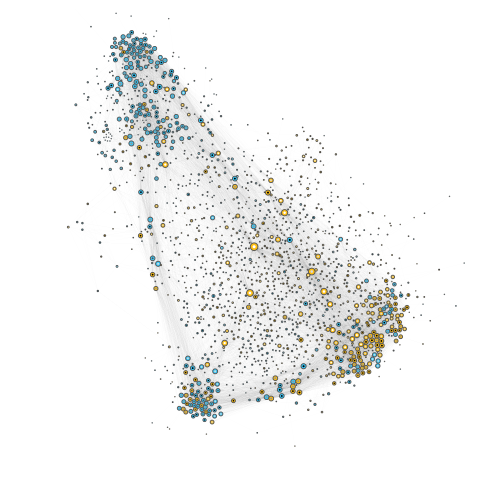

In [ ]:
import netwulf as nw
import numpy as np

size_nodes_by = 'degree'
max_node_size = 25

G = networks_uni['directed'].copy()
node_sizes = pd.Series({i:(np.log2(j+2))**1.5 for i,j in G.degree()})
nx.set_node_attributes(G, node_sizes, 'size')
nx.set_node_attributes(G, attributes['is_chiral_color'], 'group')

print(G)
fig = plt.figure(figsize=(12,12), layout='constrained')
stylized_network, config = nw.visualize(G, config={'node_label_color': '#000000', 'node_gravity': 0.0, 
                                'link_alpha': 0.005, 'link_color': '#000000', 'zoom': 0.60, 'node_charge': -100,
                                'scale_node_size_by_strength': False, 'node_size_variation': 1,
                                'node_size': max_node_size, 'link_distance':25, 'node_stroke_width': 2})
fig, ax = nw.draw_netwulf(stylized_network)

a = stylized_network.copy()
a['nodeStrokeWidth'] = 0.0
for i in list(range(len(a['nodes']))):
    a['nodes'][i]['radius'] = a['nodes'][i]['radius'] * 0.4
    a['nodes'][i]['color'] = attributes['gen_color'].loc[a['nodes'][i]['id']]

nw.draw_netwulf(a, fig=fig, ax=ax, draw_links=False)

plt.show()

['C00175', 'C00205', 'C00238', 'C05359', 'C05684', 'C06232', 'C17023', 'C19609']
Found C21389
DiGraph with 4400 nodes and 38825 edges
['C00080', 'C00209', 'C14819', 'C00069', 'C01326', 'C00022', 'C00042', 'C00160', 'C00014', 'C00011', 'C00697', 'C00161', 'C14818', 'C00059', 'C01324', 'C01353', 'C00033', 'C00076', 'C00698', 'C00058', 'C00288', 'C00009', 'C19806', 'C00383', 'C00071', 'C01335', 'C01328', 'C00111', 'C00023', 'C00070', 'C00048', 'C01528', 'C00708', 'C00067', 'C00305', 'C19610', 'C01327', 'C00488', 'C00001', 'C00036', 'C00028', 'C00030', 'C00417', 'C00282', 'C06547', 'C01330', 'C00026', 'C00027', 'C00122', 'C20396', 'C01732', 'C00283', 'C19611']
53
['C02362', 'C00133', 'C02798', 'C00093', 'C00988', 'C01384', 'C00226', 'C03459', 'C01438', 'C06793', 'C06033', 'C00409', 'C02167', 'C00405', 'C04115', 'C01417', 'C15973', 'C01044', 'C00118', 'C02107', 'C02634', 'C20969', 'C00511', 'C00025', 'C06455', 'C04131', 'C06393', 'C02214', 'C02311', 'C01370', 'C00065', 'C01251', 'C00222', '

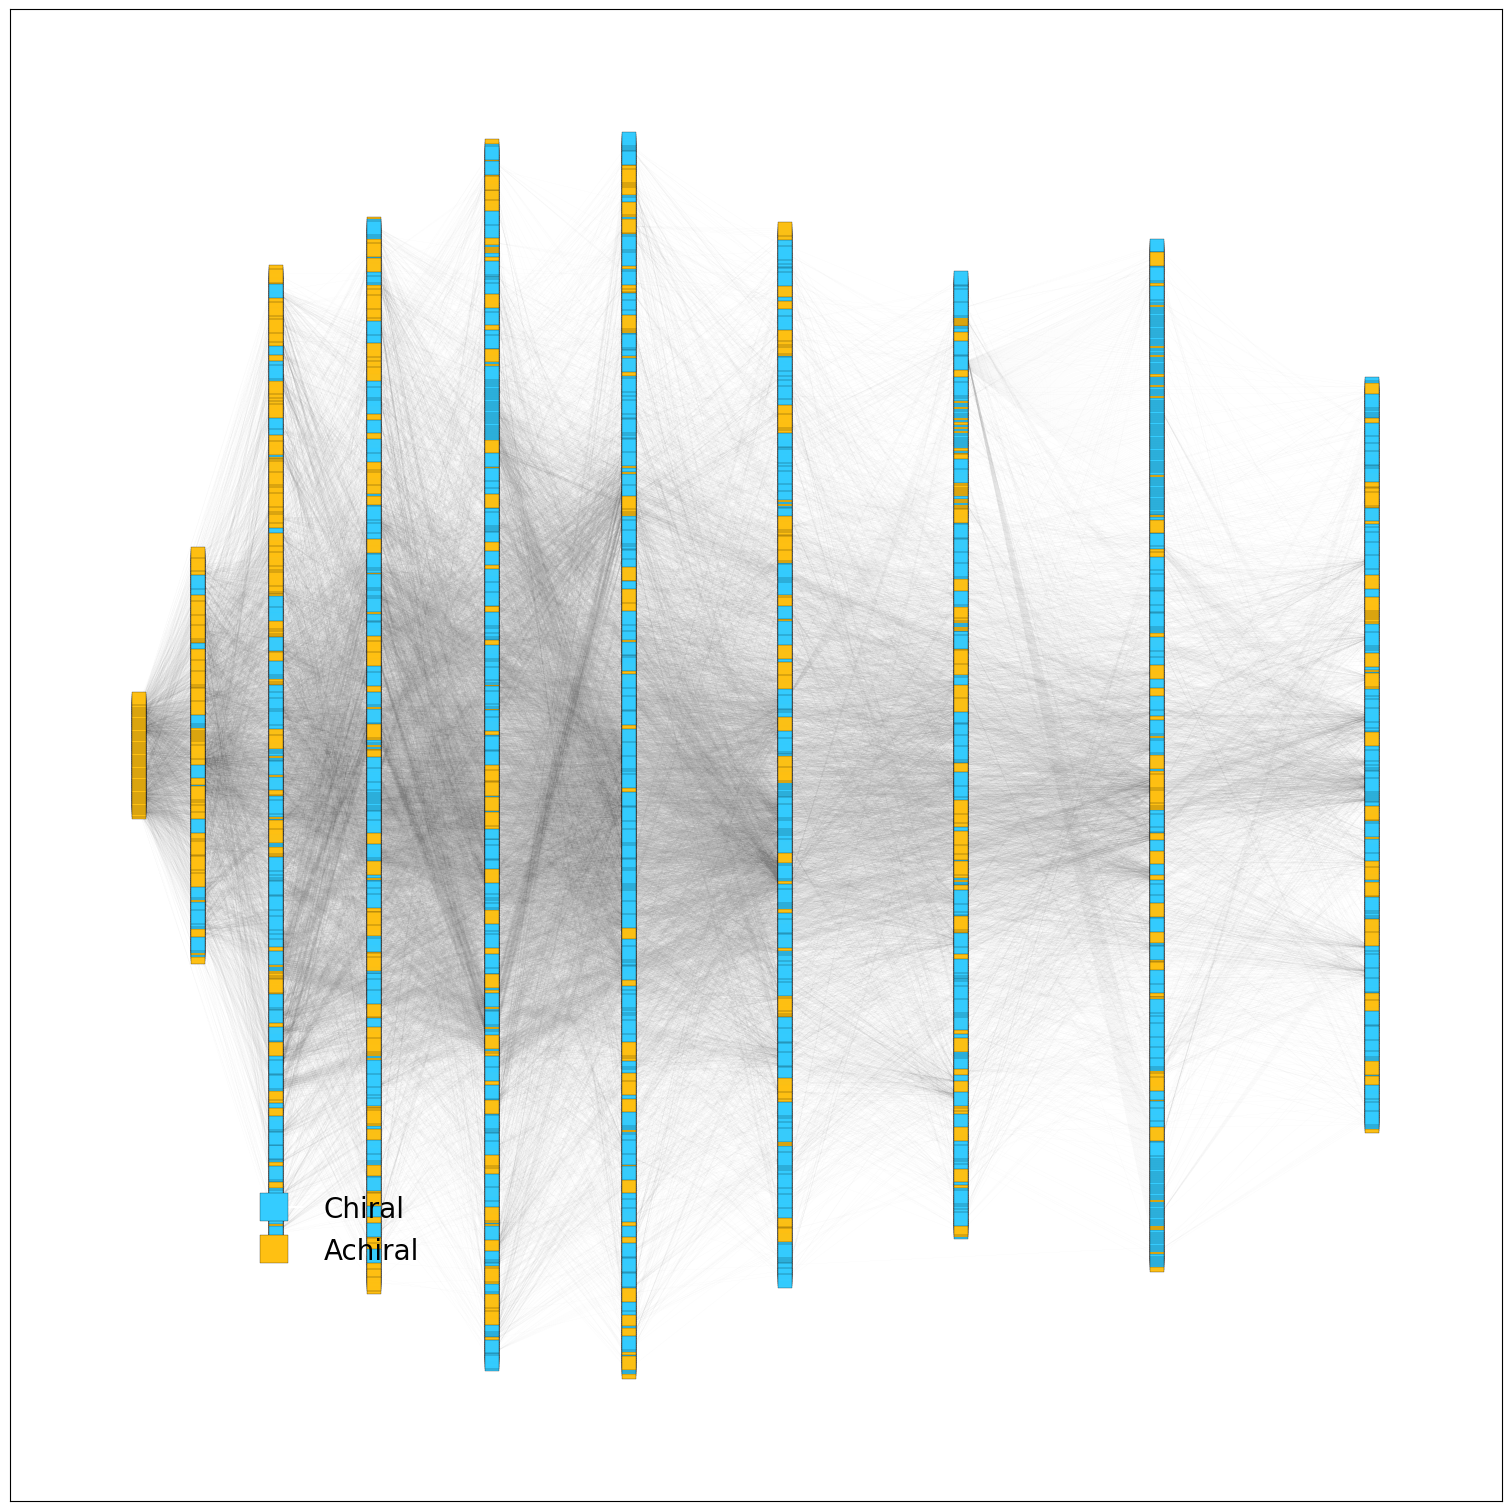

In [169]:
from netgraph import Graph, get_multipartite_layout


#attributes['test'] = (attributes['precursor_out_degree_chiral']/(attributes['is_chiral']-0.5)).filter(like='C').sort_values()
#sortby = ['is_chiral', 'test']
show = 'impactful_precursor'
rotate = False

G1 = networks_uni[show] #using impactful_precursor from network generation

#Remove G nodes that are not in attributes df
nodes_to_keep = attributes.index.to_list()
nodes_to_remove = [n for n in nodes_to_keep if n not in G1.nodes()]
print(nodes_to_remove)
G1.remove_nodes_from(nodes_to_remove)

nx.set_node_attributes(G1, attributes['is_chiral_color'], 'is_chiral_color')

if "C21389" in G1.nodes():
    print("Found C21389")
print(G1)

layers = [list(i) for i in attributes.loc[list(G1.nodes())].groupby(by='gen').groups.values()][:-1]
for layer in layers:
    if "C21389" in layer:
        print(f"Found C21389")
    print(layer)
    print(len(layer))


pos = get_multipartite_layout(edges=list(G1.edges), layers=layers, reduce_edge_crossings=True)
#for i in layers[-1]: del pos[i] # remove last layer
for n in pos.keys(): pos[n][0] = (pos[n][0]+0.2)**2 # spread out later gens to reduce extreme angles 
if rotate: pos = {i:j[::-1] for i,j in pos.items()}

print(pos)
#print(pos["C21389"])

fig, ax = plt.subplots(figsize=(15,15), layout='constrained')
nx.draw_networkx(G1.subgraph(pos.keys()), pos=pos, ax=ax, edge_color=[0.5,0.5,0.5,0.5],
                  node_color=list(gna(G1.subgraph(pos.keys()), 'is_chiral_color').values()),  
                  edgecolors='k', width=0.01, arrows=False,
                  linewidths=0.2, node_size=100, node_shape='s', alpha=0.99,
                  with_labels=False)

# nx.draw_networkx_nodes(G1, pos=pos, ax=ax, node_color=list(gna(G1.subgraph(pos.keys()), 'is_chiral_color').values()), 
#                        node_size=100, node_shape='s', alpha=1.00) #draw nodes
# [nx.draw_networkx_edges(G1, pos=pos, arrows=False, width=0.05,
#                         alpha=0.05)] #loop through edges and draw them


plt.legend(loc='lower left', borderpad=8, frameon=False, handles=[plt.Line2D([0], [0], marker='s', color='w', markeredgecolor='k', markeredgewidth=0.2, markerfacecolor='#34CCFF', markersize=20, label='Chiral'),
                    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='#FFC012', markeredgecolor='k', markeredgewidth=0.2, markersize=20, label='Achiral')], prop={'size': 20})
#plt.savefig('fig3_expansion_'+show+'_edges_minimal_crossings.svg', format='svg', facecolor='w', edgecolor='w')
plt.show()